## **Import Librerie**s

In [0]:
%pip install seaborn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [0]:
import seaborn as sns

In [0]:
sales = pd.read_csv("/Workspace/Users/soumyanalyst323@gmail.com/Retail Sales Analysis/bm_sales.csv")

In [0]:
sales.head()

,date,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0


In [0]:
stores= pd.read_csv("/Workspace/Users/soumyanalyst323@gmail.com/Retail Sales Analysis/bm_stores.csv")

In [0]:
stores.head()

,store_id,store_name,city,store_type,opening_date
0,9,BlueMart Store 09,Abu Dhabi,Mall,2017-01-01 00:00:00.000000000
1,10,BlueMart Store 10,Abu Dhabi,Mall,2017-01-31 00:00:00.000000000
2,11,BlueMart Store 11,Dubai,Mall,2017-03-02 00:00:00.000000000
3,12,BlueMart Store 12,Sharjah,Mall,2017-04-01 00:00:00.000000000
4,13,BlueMart Store 13,Sharjah,Community,2017-05-01 00:00:00.000000000


In [0]:
sku = pd.read_csv("/Workspace/Users/soumyanalyst323@gmail.com/Retail Sales Analysis/bm_skus.csv")

In [0]:
sku.head()

,sku_id,sku_name,category,subcategory,unit_price,cost_price,brand
0,1001,Electronics_Chargers_1001,Electronics,Chargers,164.56,103.44,Budget
1,1002,Dairy_Cream_1002,Dairy,Cream,13.73,8.96,Local
2,1003,Household_Cleaning Supplies_1003,Household,Cleaning Supplies,12.00,7.47,BlueMart
3,1004,Beverages_Juices_1004,Beverages,Juices,24.82,17.58,International
4,1005,Household_Paper Products_1005,Household,Paper Products,17.70,13.68,Budget


## **Data Inspection**

In [0]:
# sales
sales.head()

,date,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0


In [0]:
sales.columns

Index(['date', 'store_id', 'sku_id', 'customer_id', 'quantity', 'unit_price',
       'total_value', 'channel', 'discount_pct'],
      dtype='object')

In [0]:
sales.shape

(641843, 9)

In [0]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 641843 entries, 0 to 641842
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   date          641843 non-null  object 
 1   store_id      641843 non-null  int64  
 2   sku_id        641843 non-null  int64  
 3   customer_id   482022 non-null  float64
 4   quantity      641843 non-null  int64  
 5   unit_price    641843 non-null  float64
 6   total_value   641843 non-null  float64
 7   channel       641843 non-null  object 
 8   discount_pct  641843 non-null  float64
dtypes: float64(4), int64(3), object(2)
memory usage: 44.1+ MB


In [0]:
sales.describe()

,store_id,sku_id,customer_id,quantity,unit_price,total_value,discount_pct
count,641843.000000,641843.000000,482022.000000,641843.000000,641843.000000,641843.000000,641843.000000
mean,25.491081,1100.547835,2504.986828,2.613120,44.109242,114.069845,5.411316
std,14.437269,57.684158,1442.340254,1.481563,48.984342,157.206354,8.664765
min,1.000000,1001.000000,1.000000,1.000000,1.700000,1.700000,0.000000
25%,13.000000,1051.000000,1260.000000,1.000000,14.280000,27.320000,0.000000
50%,25.000000,1101.000000,2507.000000,2.000000,24.330000,57.660000,0.000000
75%,38.000000,1150.000000,3752.000000,4.000000,49.570000,129.550000,10.000000
max,50.000000,1200.000000,5000.000000,6.000000,245.380000,1472.280000,35.000000


In [0]:
# product
sku.head()

,sku_id,sku_name,category,subcategory,unit_price,cost_price,brand
0,1001,Electronics_Chargers_1001,Electronics,Chargers,164.56,103.44,Budget
1,1002,Dairy_Cream_1002,Dairy,Cream,13.73,8.96,Local
2,1003,Household_Cleaning Supplies_1003,Household,Cleaning Supplies,12.00,7.47,BlueMart
3,1004,Beverages_Juices_1004,Beverages,Juices,24.82,17.58,International
4,1005,Household_Paper Products_1005,Household,Paper Products,17.70,13.68,Budget


In [0]:
sku.columns

Index(['sku_id', 'sku_name', 'category', 'subcategory', 'unit_price',
       'cost_price', 'brand'],
      dtype='object')

In [0]:
sku.shape

(200, 7)

In [0]:
sku.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   sku_id       200 non-null    int64  
 1   sku_name     200 non-null    object 
 2   category     200 non-null    object 
 3   subcategory  200 non-null    object 
 4   unit_price   200 non-null    float64
 5   cost_price   200 non-null    float64
 6   brand        200 non-null    object 
dtypes: float64(2), int64(1), object(4)
memory usage: 11.1+ KB


In [0]:
sku.describe()

,sku_id,unit_price,cost_price
count,200.000000,200.000000,200.000000
mean,1100.500000,46.682300,31.060100
std,57.879185,51.590508,34.435869
min,1001.000000,2.610000,1.680000
25%,1050.750000,15.242500,10.065000
50%,1100.500000,25.910000,17.115000
75%,1150.250000,51.270000,34.322500
max,1200.000000,245.380000,187.670000


In [0]:
# Stores
stores.head()

,store_id,store_name,city,store_type,opening_date
0,9,BlueMart Store 09,Abu Dhabi,Mall,2017-01-01 00:00:00.000000000
1,10,BlueMart Store 10,Abu Dhabi,Mall,2017-01-31 00:00:00.000000000
2,11,BlueMart Store 11,Dubai,Mall,2017-03-02 00:00:00.000000000
3,12,BlueMart Store 12,Sharjah,Mall,2017-04-01 00:00:00.000000000
4,13,BlueMart Store 13,Sharjah,Community,2017-05-01 00:00:00.000000000


In [0]:
stores.columns

Index(['store_id', 'store_name', 'city', 'store_type', 'opening_date'], dtype='object')

In [0]:
stores.shape

(50, 5)

In [0]:
stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   store_id      50 non-null     int64 
 1   store_name    50 non-null     object
 2   city          50 non-null     object
 3   store_type    50 non-null     object
 4   opening_date  50 non-null     object
dtypes: int64(1), object(4)
memory usage: 2.1+ KB


In [0]:
stores.describe()

,store_id
count,50.00000
mean,25.50000
std,14.57738
min,1.00000
25%,13.25000
50%,25.50000
75%,37.75000
max,50.00000


### **Data Quality Assesment**

In [0]:
# sales null values
sales.isnull().sum()

date                 0
store_id             0
sku_id               0
customer_id     159821
quantity             0
unit_price           0
total_value          0
channel              0
discount_pct         0
dtype: int64

In [0]:
# product null values
sku.isnull().sum()

sku_id         0
sku_name       0
category       0
subcategory    0
unit_price     0
cost_price     0
brand          0
dtype: int64

In [0]:
# stores null values
stores.isnull().sum()

store_id        0
store_name      0
city            0
store_type      0
opening_date    0
dtype: int64

In [0]:
# sales duplicated values
sales.duplicated().sum()

np.int64(45)

In [0]:
# Product duplicated values
sku.duplicated().sum()

np.int64(0)

In [0]:
# Store duplicated values 
stores.duplicated().sum()

np.int64(0)

In [0]:
sales[sales.duplicated(keep =False)]['customer_id'].isnull().sum()

np.int64(87)

In [0]:
# Referential Integrity Check
sales['store_id'].isin(stores['store_id']).all()

np.True_

In [0]:
sales['sku_id'].isin(sku['sku_id']).all()

np.True_

### **Data Cleaning**

In [0]:
# Sales date column change data type
sales['date'] = pd.to_datetime(sales['date'])

In [0]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 641843 entries, 0 to 641842
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   date          641843 non-null  datetime64[ns]
 1   store_id      641843 non-null  int64         
 2   sku_id        641843 non-null  int64         
 3   customer_id   482022 non-null  float64       
 4   quantity      641843 non-null  int64         
 5   unit_price    641843 non-null  float64       
 6   total_value   641843 non-null  float64       
 7   channel       641843 non-null  object        
 8   discount_pct  641843 non-null  float64       
dtypes: datetime64[ns](1), float64(4), int64(3), object(1)
memory usage: 44.1+ MB


In [0]:
# store date column
stores['opening_date'] = pd.to_datetime(stores['opening_date'])

In [0]:
# Drop duplicated value from sales
sales.drop_duplicates(inplace=True)

In [0]:
sales.duplicated().sum()

np.int64(0)

In [0]:
# data consistency check
sku['category'].value_counts()

category
Electronics      43
Snacks           39
Household        30
Dairy            25
Grocery          25
Personal Care    22
Beverages        16
Name: count, dtype: int64

In [0]:
sku['category'].unique()

array(['Electronics', 'Dairy', 'Household', 'Beverages', 'Personal Care',
       'Grocery', 'Snacks'], dtype=object)

In [0]:
stores.columns

Index(['store_id', 'store_name', 'city', 'store_type', 'opening_date'], dtype='object')

In [0]:
stores['city'].unique()

array(['Abu Dhabi', 'Dubai', 'Sharjah'], dtype=object)

In [0]:
stores['city'].value_counts()

city
Dubai        28
Abu Dhabi    14
Sharjah       8
Name: count, dtype: int64

## Joining The Tables
 -  Sales + Stores + Product

In [0]:
sales.columns

Index(['date', 'store_id', 'sku_id', 'customer_id', 'quantity', 'unit_price',
       'total_value', 'channel', 'discount_pct'],
      dtype='object')

In [0]:
sku.columns

Index(['sku_id', 'sku_name', 'category', 'subcategory', 'unit_price',
       'cost_price', 'brand'],
      dtype='object')

In [0]:
# Join sales table from Product Table
df = pd.merge(sales, sku, on = 'sku_id', how = 'left' )
df.head()

,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,channel,discount_pct,sku_name,category,subcategory,unit_price_y,cost_price,brand
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,Electronics,Batteries,245.38,139.58,Premium
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,Household,Cleaning Supplies,21.16,15.32,BlueMart
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,Electronics,Cables,196.24,126.30,BlueMart
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,Snacks,Chips,7.98,5.29,BlueMart


In [0]:
# Merge the df file store table
final_df = pd.merge(df, stores, on ='store_id', how = 'left' )
final_df.head()

,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,channel,discount_pct,sku_name,category,subcategory,unit_price_y,cost_price,brand,store_name,city,store_type,opening_date
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,Electronics,Batteries,245.38,139.58,Premium,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,Household,Cleaning Supplies,21.16,15.32,BlueMart,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,Electronics,Cables,196.24,126.30,BlueMart,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,Snacks,Chips,7.98,5.29,BlueMart,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000


## Analyze and Visualize
 - How are sales changing over time?
 - Which categories generate the highest sales and profit?
 - Which products are the most profitable?
 - Which stores and cities are performering best?
 - Which  salea chennel contributes the most revenue?

### **01. How are sales changing over time?**

In [0]:
final_df.columns

Index(['date', 'store_id', 'sku_id', 'customer_id', 'quantity', 'unit_price_x',
       'total_value', 'channel', 'discount_pct', 'sku_name', 'category',
       'subcategory', 'unit_price_y', 'cost_price', 'brand', 'store_name',
       'city', 'store_type', 'opening_date'],
      dtype='object')

In [0]:
monthly_sales = final_df.groupby(final_df['date'].dt.to_period("M"))['total_value'].sum()
monthly_sales 

date
2021-01    1980260.06
2021-02    1985618.84
2021-03     830610.94
2021-04    1205290.58
2021-05    1714872.08
2021-06    1102448.76
2021-07    1593500.17
2021-08    1534914.44
2021-09     743017.49
2021-10     746654.89
2021-11     880963.22
2021-12    1010790.03
2022-01    1975515.34
2022-02    1670850.70
2022-03     744344.15
2022-04    1496533.15
2022-05    1272515.50
2022-06    1047882.41
2022-07    1551056.51
2022-08    1597754.29
2022-09     762628.04
2022-10     832061.60
2022-11     802755.82
2022-12    1147061.74
2023-01    2014695.08
2023-02    1655498.63
2023-03     995092.53
2023-04    1396463.52
2023-05    1114112.14
2023-06    1124356.88
2023-07    1401382.51
2023-08    1452965.16
2023-09     722727.15
2023-10     804104.01
2023-11     794452.48
2023-12    1099200.26
2024-01    2189798.22
2024-02    1812283.81
2024-03    1330568.12
2024-04    1200399.59
2024-05    1127492.38
2024-06    1176729.44
2024-07    1571128.50
2024-08    1553422.98
2024-09     755062.64
2024-

In [0]:
monthly_sales.index = monthly_sales.index.astype(str)

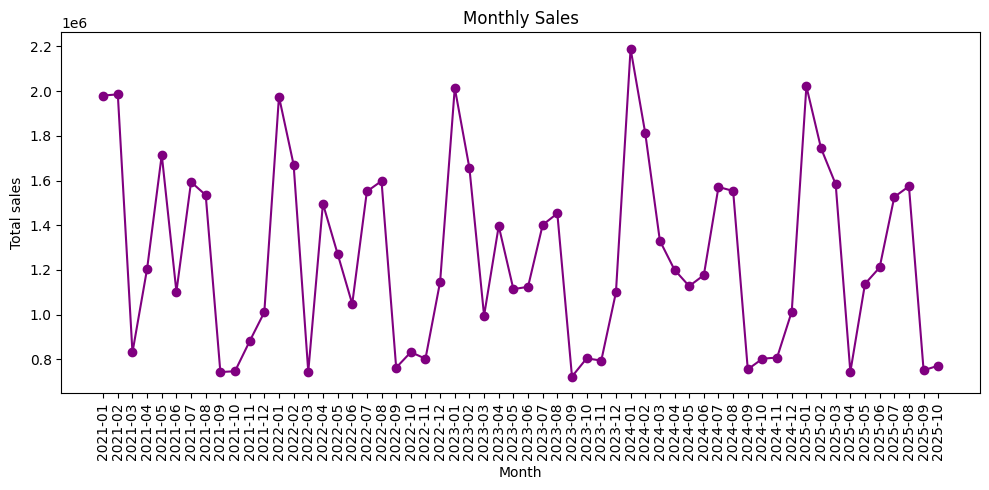

In [0]:
# Visualization line - Chart
plt.figure(figsize=(10,5))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o', color='purple')

plt.title('Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total sales')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#### **02. Which categories generate the highest sales and profit?**

In [0]:
# profit = total_value - (cost_price * quantity)
final_df['profit'] = final_df['total_value'] - final_df['cost_price'] * final_df['quantity']
final_df.head(3)

,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,channel,discount_pct,sku_name,category,subcategory,unit_price_y,cost_price,brand,store_name,city,store_type,opening_date,profit
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,6.46
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,Electronics,Batteries,245.38,139.58,Premium,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171,206.97
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,Household,Cleaning Supplies,21.16,15.32,BlueMart,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,2.67


In [0]:
category_pref = final_df.groupby('category').agg(total_sales = ('total_value', 'sum'),
                                  total_profit = ('profit', 'sum')).sort_values('total_sales', ascending = False)

category_pref

,total_sales,total_profit
category,,
Electronics,40790950.89,11848265.14
Household,8190735.92,2360418.07
Personal Care,8181799.29,2115959.34
Grocery,5564702.41,1661022.56
Snacks,4321275.25,1299444.11
Dairy,4238161.64,1237884.73
Beverages,1922157.59,574416.61


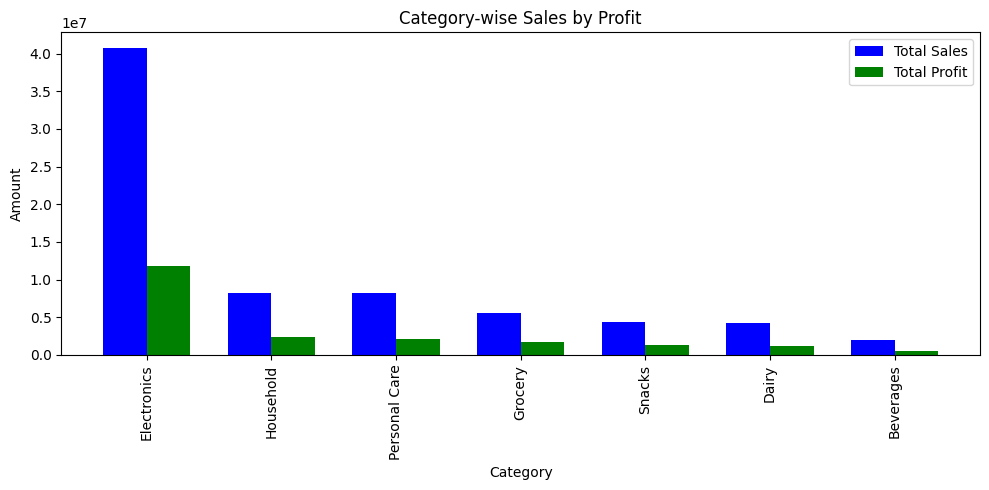

In [0]:
# Visualization Bar Chart
x  = np.arange(len(category_pref)) 
width = 0.35

plt.figure(figsize=(10,5))
plt.bar(x - width/2, category_pref['total_sales'], width =width, label='Total Sales', color = 'blue')
plt.bar(x + width/2, category_pref['total_profit'], width =width, label='Total Profit', color = 'green')

plt.title('Category-wise Sales by Profit')
plt.xlabel('Category')
plt.ylabel('Amount')
plt.xticks(x , category_pref.index, rotation = 90)
plt.legend()
plt.tight_layout()
plt.show()

#### **03. Which Products are the most profitable?**

In [0]:
final_df.columns

Index(['date', 'store_id', 'sku_id', 'customer_id', 'quantity', 'unit_price_x',
       'total_value', 'channel', 'discount_pct', 'sku_name', 'category',
       'subcategory', 'unit_price_y', 'cost_price', 'brand', 'store_name',
       'city', 'store_type', 'opening_date', 'profit'],
      dtype='object')

In [0]:
product_perf = final_df.groupby('subcategory').agg(total_sales = ('total_value', 'sum'),
                                  total_profit = ('profit', 'sum')).sort_values('total_profit', ascending = False)

/home/spark-5a2b8cfd-3656-45d6-b372-9e/.ipykernel/67/command-8596456498025662-4290466065:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = top_10_profitable.index, y = top_10_profitable['total_profit'], palette='mako')


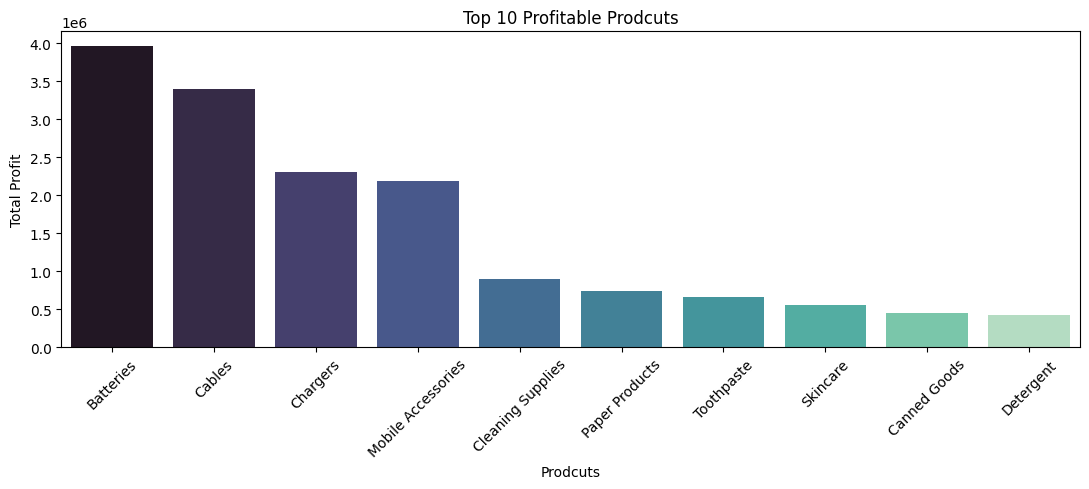

In [0]:
# Top 10 product profitable
top_10_profitable = product_perf.head(10)

# VISUALIZATION -Bar CHART
plt.figure(figsize=(11,5))
sns.barplot(x = top_10_profitable.index, y = top_10_profitable['total_profit'], palette='mako')
plt.title('Top 10 Profitable Prodcuts')
plt.xlabel('Prodcuts')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Insights:
-  **Betteries has the most profitable product folloewd by cables, chargers, and mobile accessories.**
-  **Detergent, Skincare, and Canned Goods are the lowet profitable prodcuts.**

#### 04. Which stores and cities are performering best?

In [0]:
store_cities_perf = final_df.groupby(['store_name'])["total_value"].sum().sort_values(ascending=False)
store_cities_perf.head(10)

store_name
BlueMart Store 41    1500094.91
BlueMart Store 11    1495245.74
BlueMart Store 49    1494703.15
BlueMart Store 44    1493356.50
BlueMart Store 04    1492536.75
BlueMart Store 37    1489346.54
BlueMart Store 35    1486546.13
BlueMart Store 08    1486405.93
BlueMart Store 17    1484028.19
BlueMart Store 19    1481028.59
Name: total_value, dtype: float64

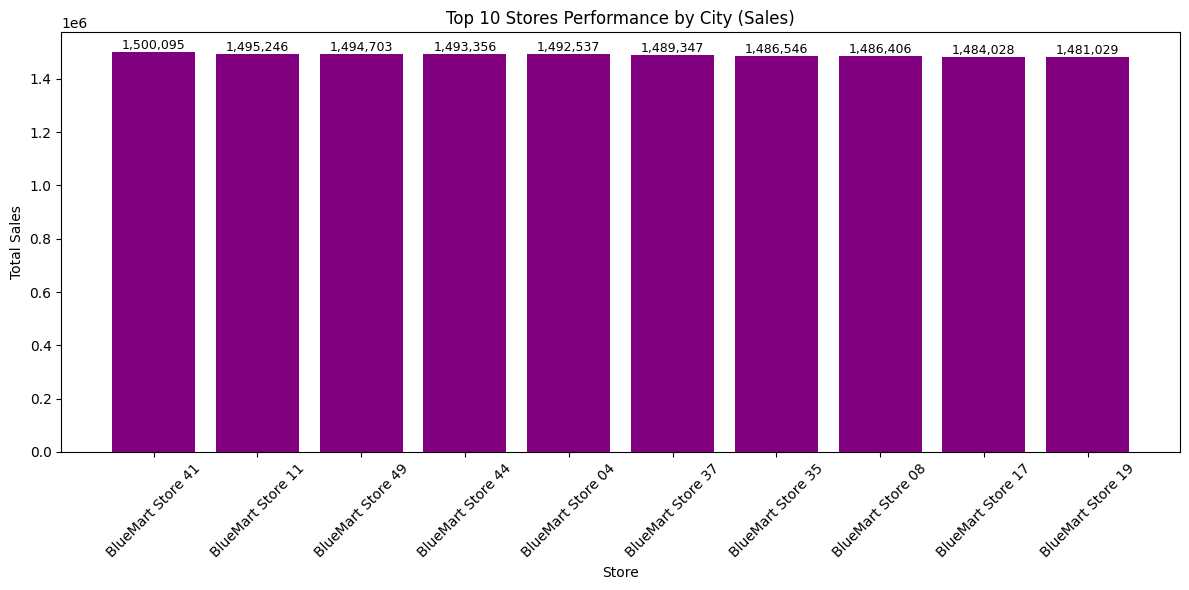

In [0]:
# top 10 stores by city
top_10_stores = store_cities_perf.head(10)
top_10_stores

plt.figure(figsize=(12, 6))
bars = plt.bar(top_10_stores.index, top_10_stores.values, color = 'purple')
plt.title('Top 10 Stores Performance by City (Sales)')
plt.xlabel('Store')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

# Add data labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height:,.0f}',
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [0]:
city_perf = final_df.groupby("city")['total_value'].sum().sort_values(ascending=False)
city_perf

city
Dubai        41041586.36
Abu Dhabi    20492594.10
Sharjah      11675602.53
Name: total_value, dtype: float64

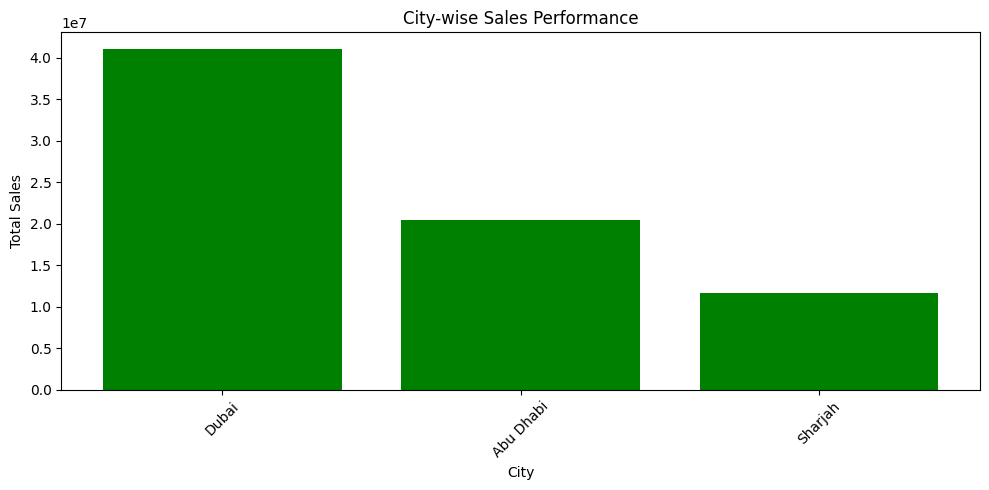

In [0]:
plt.figure(figsize=(10,5))
plt.bar(city_perf.index, city_perf.values, color = 'green')
plt.title('City-wise Sales Performance')
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### **05. Which salea chennel contributes the most revenue?**

In [0]:
# Chack the channel column
channel_perf = final_df.groupby("channel")["total_value"].sum().sort_values(ascending=False)
channel_perf 

channel
Store        30227603.54
Website      20299836.60
MobileApp    13097435.70
Amazon.ae     6470717.92
Noon          3114189.23
Name: total_value, dtype: float64

/home/spark-5a2b8cfd-3656-45d6-b372-9e/.ipykernel/67/command-8596456498025700-4248398035:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = channel_perf.values, y = channel_perf.index, palette='viridis')


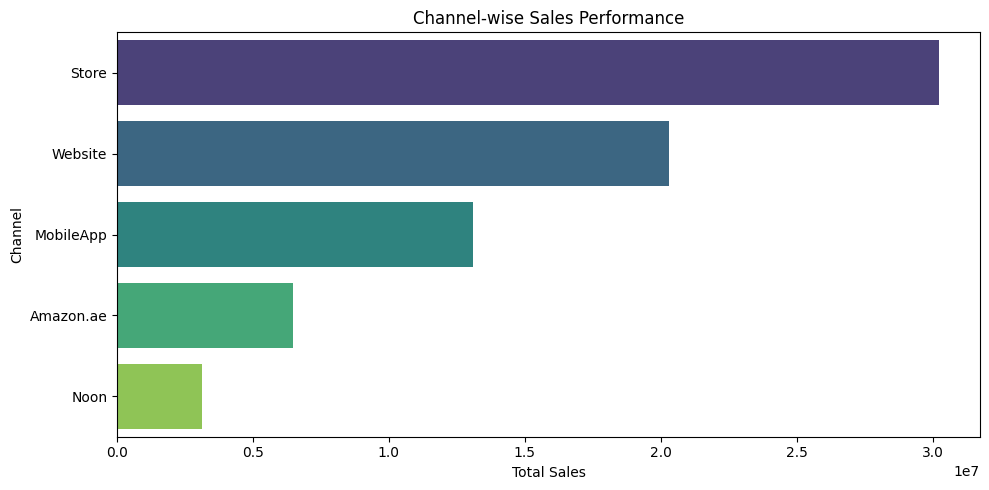

In [0]:
# Visualization - horizontal bar chart
plt.figure(figsize=(10,5))
sns.barplot(x = channel_perf.values, y = channel_perf.index, palette='viridis')
plt.title('Channel-wise Sales Performance')
plt.xlabel('Total Sales')
plt.ylabel('Channel')
plt.tight_layout()
plt.show()

## **Key Insights & Recommendations**

### **1. Monthly Sales Trend**
**Insights:**
- Total sales across Jan 2021 – Oct 2025: **$73.2M** (avg ~$1.26M/month)
- Strong **seasonal pattern**: January–February are peak months (~$1.7–2.2M), while **September is consistently the weakest** month (~$722K–762K)
- Yearly revenue is relatively flat: 2021 ($15.3M) → 2022 ($14.9M) → 2023 ($14.6M) → 2024 ($15.3M), with a slight dip in 2022–2023 before recovery
- Peak single month: **Jan 2024 ($2.19M)**; lowest: **Sep 2023 ($722K)**

**Recommendations:**
- Launch targeted promotions or campaigns during the **September trough** to boost off-season sales
- Capitalize on Jan–Feb peaks with adequate inventory planning and seasonal staffing
- Investigate the 2022–2023 revenue decline — was it competition, pricing, or macro factors?

---

### **2. Category Performance**
**Insights:**
- **Electronics dominates** with $40.8M in sales and $11.8M in profit — roughly **5× larger** than any other category
- Household ($8.2M) and Personal Care ($8.2M) are distant second and third
- Profit margins are remarkably consistent across all categories: **25.9% – 30.1%**
- **Snacks** has the highest margin (30.1%); **Personal Care** has the lowest (25.9%)

**Recommendations:**
- Electronics is the revenue engine — protect this category with competitive pricing and strong supplier relationships
- **Snacks and Beverages** offer the best margin-to-revenue ratio; consider expanding product variety to grow these high-margin categories
- Personal Care margin (25.9%) is below average — review pricing or supplier costs

---

### **3. Most Profitable Products**
**Insights:**
- **Batteries** ($3.96M profit), **Cables** ($3.39M), **Chargers** ($2.31M), and **Mobile Accessories** ($2.18M) are the top 4 — all Electronics subcategories
- These 4 products alone generate **$11.8M in profit**, matching the entire Electronics category profit
- Lowest-profit items: Coffee ($32K), Water ($41K), Nuts ($132K), Tea ($137K), Juices ($137K)

**Recommendations:**
- Prioritize shelf space and inventory for the top 4 Electronics accessories — they are the profit backbone
- Consider bundling strategies (e.g., charger + cable + battery packs) to increase average order value
- Evaluate whether low-profit items like Coffee and Water are worth the shelf/operational cost, or if they should be replaced with higher-margin alternatives

---

### **4. Store Performance**
**Insights:**
- Top 10 stores are **extremely evenly distributed** — all between $1.48M and $1.50M in sales
- No single store dominates; performance is balanced across locations
- BlueMart Store 41 leads marginally at $1.50M

**Recommendations:**
- The even distribution suggests a healthy, well-managed store network
- Focus on **lifting the bottom-performing stores** rather than just the top 10 — identify what the top stores do differently (staffing, layout, local marketing)
- Share best practices from Store 41 across the network

---

### **5. City Performance**
**Insights:**
- **Dubai generates 56% of total revenue** ($41.0M), more than Abu Dhabi and Sharjah combined
- Abu Dhabi: $20.5M (28%), Sharjah: $11.7M (16%)
- Heavy geographic concentration in Dubai

**Recommendations:**
- Dubai is the primary market — ensure supply chain resilience and premium service levels there
- **Abu Dhabi and Sharjah are underpenetrated** relative to Dubai — expansion or intensified marketing in these cities could unlock growth
- Consider city-specific product assortments based on local demographics and preferences

---

### **6. Sales Channel Performance**
**Insights:**
- **Physical stores remain the largest channel** at $30.2M (41.3% of revenue)
- Digital channels combined (Website 27.7% + MobileApp 17.9% + Amazon 8.8% + Noon 4.3%) account for **58.7%** of total sales
- Third-party marketplaces (Amazon.ae + Noon) contribute only 13.1%
- Website alone outperforms MobileApp by ~1.5×

**Recommendations:**
- Invest in **MobileApp improvements** — its 17.9% share lags the website; UX enhancements and push-notification campaigns could close the gap
- Evaluate the ROI of third-party marketplace listings (Amazon/Noon) — their 13.1% share may not justify the commission fees and margin erosion; consider redirecting that traffic to the owned website/app
- Stores are still critical — use them as fulfillment hubs for online orders (click-and-collect) to blend physical and digital strengths

---

### **Overall Strategic Recommendations**
1. **Double down on Electronics accessories** — they are the profit core of the business
2. **Smooth the seasonal dip** — September consistently underperforms; targeted promotions can stabilize revenue
3. **Expand in Abu Dhabi & Sharjah** — Dubai is saturated; the other cities offer growth headroom
4. **Strengthen owned digital channels** — shift spend from third-party marketplaces to the website and mobile app
5. **Optimize low-profit SKUs** — audit Coffee, Water, and other low-margin items for replacement or discontinuation
6. **Leverage the balanced store network** — share best practices from top stores to lift underperformers

### **06. Which high selling-products are at risk of stockout (low-inventory)?**


In [0]:
final_df

,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,channel,discount_pct,sku_name,category,subcategory,unit_price_y,cost_price,brand,store_name,city,store_type,opening_date,profit
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392,6.46
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,Electronics,Batteries,245.38,139.58,Premium,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171,206.97
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,Household,Cleaning Supplies,21.16,15.32,BlueMart,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196,2.67
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,Electronics,Cables,196.24,126.30,BlueMart,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000,419.64
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,Snacks,Chips,7.98,5.29,BlueMart,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000,2.69
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
641793,2025-10-31,29,1102,2525.0,3,21.54,64.62,Website,0.0,Snacks_Biscuits_1102,Snacks,Biscuits,21.54,13.18,Premium,BlueMart Store 29,Abu Dhabi,Mall,2017-06-28 01:10:14.634146342,25.08
641794,2025-10-31,13,1029,3091.0,2,27.90,55.80,Amazon.ae,0.0,Grocery_Canned Goods_1029,Grocery,Canned Goods,27.90,19.78,Premium,BlueMart Store 13,Sharjah,Community,2017-05-01 00:00:00.000000000,16.24
641795,2025-10-31,8,1180,2345.0,1,8.40,8.40,Store,0.0,Grocery_Spices_1180,Grocery,Spices,8.40,6.20,Premium,BlueMart Store 08,Sharjah,Mall,2017-12-28 00:00:00.000000000,2.20
641796,2025-10-31,27,1158,1945.0,3,7.27,21.81,Store,0.0,Snacks_Crackers_1158,Snacks,Crackers,7.27,5.31,Local,BlueMart Store 27,Dubai,High Street,2017-06-10 05:51:13.170731708,5.88


## Introduction to Inventory Table

In [0]:
inventory = pd.read_csv("/Workspace/Users/soumyanalyst323@gmail.com/Retail Sales Analysis/bm_inventory.csv")

In [0]:
inventory.head()

,store_id,sku_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
0,9,1101,300,92,46,2025-10-18,2025-10-31
1,9,1021,425,162,81,2025-10-21,2025-10-31
2,9,1200,252,85,42,2025-09-14,2025-10-31
3,9,1041,220,87,43,2025-10-13,2025-10-31
4,9,1092,170,80,40,2025-09-12,2025-10-31


In [0]:
inventory.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8735 entries, 0 to 8734
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   store_id           8735 non-null   int64 
 1   sku_id             8735 non-null   int64 
 2   stock_on_hand      8735 non-null   int64 
 3   reorder_point      8735 non-null   int64 
 4   safety_stock       8735 non-null   int64 
 5   last_restock_date  8735 non-null   object
 6   snapshot_date      8735 non-null   object
dtypes: int64(5), object(2)
memory usage: 477.8+ KB


In [0]:
product_sales = final_df.groupby('sku_id')['quantity'].sum().reset_index()
product_sales

,sku_id,quantity
0,1001,8545
1,1002,8445
2,1003,8388
3,1004,8301
4,1005,8563
...,...,...
195,1196,8621
196,1197,8358
197,1198,8322
198,1199,8283


In [0]:
risk_df = product_sales.merge(inventory,on='sku_id', how= 'left')
risk_df.head()

,sku_id,quantity,store_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
0,1001,8545,9,88,40,20,2025-09-26,2025-10-31
1,1001,8545,10,196,68,34,2025-09-06,2025-10-31
2,1001,8545,11,111,52,26,2025-10-29,2025-10-31
3,1001,8545,12,200,71,35,2025-10-17,2025-10-31
4,1001,8545,13,62,25,12,2025-09-05,2025-10-31


In [0]:
risk_df.shape

(8735, 8)

In [0]:
high_sales_low_stock = risk_df[(risk_df['quantity']> risk_df['quantity'].median()) & (risk_df['stock_on_hand']<risk_df['stock_on_hand'].median())]
high_sales_low_stock

,sku_id,quantity,store_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
0,1001,8545,9,88,40,20,2025-09-26,2025-10-31
2,1001,8545,11,111,52,26,2025-10-29,2025-10-31
4,1001,8545,13,62,25,12,2025-09-05,2025-10-31
6,1001,8545,15,85,31,15,2025-08-14,2025-10-31
7,1001,8545,16,141,43,21,2025-10-13,2025-10-31
...,...,...,...,...,...,...,...,...
8532,1196,8621,1,144,45,22,2025-09-01,2025-10-31
8534,1196,8621,27,144,64,32,2025-09-14,2025-10-31
8544,1196,8621,4,139,61,30,2025-09-09,2025-10-31
8549,1196,8621,40,122,53,26,2025-09-08,2025-10-31


#### **07. Which products have fallen below their reorder point?**

In [0]:
low_stock = inventory[inventory['stock_on_hand']<inventory['reorder_point']]
low_stock

,store_id,sku_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date


#### **08. Which products have have high sales but low profit?**

In [0]:
product_summary  = final_df.groupby("sku_name").agg(total_sales=("total_value","sum"),
                               total_profit=("profit","sum"))
product_summary                               

,total_sales,total_profit
sku_name,,
Beverages_Coffee_1006,96824.87,16523.67
Beverages_Coffee_1141,67713.90,15553.05
Beverages_Juices_1004,192823.87,46892.29
Beverages_Juices_1012,108914.42,43695.73
Beverages_Juices_1020,76798.25,18193.53
...,...,...
Snacks_Nuts_1081,81668.99,18086.61
Snacks_Nuts_1111,103005.40,19404.70
Snacks_Nuts_1130,133901.03,34691.11


In [0]:
high_sales_low_profit = product_summary.loc[(product_summary['total_sales'] > product_summary['total_sales'].median()) 
                                            & (product_summary['total_profit']< product_summary['total_profit'].median())]

high_sales_low_profit

,total_sales,total_profit
sku_name,,
Dairy_Cream_1015,216990.20,53024.38
Grocery_Canned Goods_1029,221385.97,53295.53
Grocery_Pasta_1196,240533.99,56561.85
Grocery_Rice_1121,252178.55,36236.60
Grocery_Spices_1128,210567.09,53687.09
Household_Cleaning Supplies_1179,225473.13,59049.43
Household_Paper Products_1028,321556.41,58348.01
Personal Care_Soap_1156,279936.17,53765.73


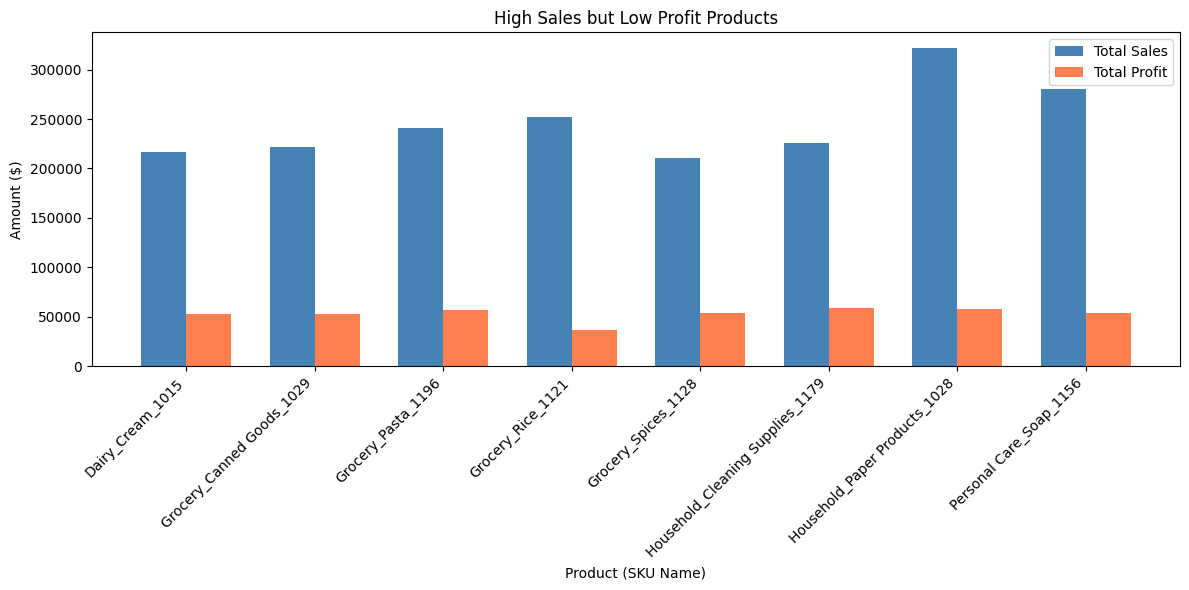

In [0]:
plt.figure(figsize=(12, 6))
x = np.arange(len(high_sales_low_profit))
bar_width = 0.35

plt.bar(x - bar_width/2, high_sales_low_profit['total_sales'], bar_width, label='Total Sales', color='steelblue')
plt.bar(x + bar_width/2, high_sales_low_profit['total_profit'], bar_width, label='Total Profit', color='coral')

plt.xticks(x, high_sales_low_profit.index, rotation=45, ha='right')
plt.title('High Sales but Low Profit Products')
plt.xlabel('Product (SKU Name)')
plt.ylabel('Amount ($)')
plt.legend()
plt.tight_layout()
plt.show()